<a href="https://colab.research.google.com/github/kunjana30/Internship-Project-2/blob/main/Task4_Trend_Analysis_Release_Year.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 4 (Medium) – Trend Analysis by Release Year

**Goal:** Analyse how Netflix content production has changed over time.

**Prerequisite:** run the Task 1 notebook first (it creates `netflix_cleaned.csv`).

| Step | What we do |
|------|-----------|
| 1 | Organise content by release year |
| 2 | Calculate yearly content releases |
| 3 | Identify growth and decline trends |
| 4 | Create trend visualisations |
| 5 | Interpret business patterns |

> ⚠️ **Important data caveat:** the dataset ends in **September 2021**, so the last year (2021) is a **partial year**.
> We flag it in every chart and leave it out of growth-rate calculations – otherwise it would look like a false "crash".

### ☁️ Google Colab / Drive setup – run this cell first
Colab's storage is **temporary**: files in `/content` disappear when the session ends, and each notebook runs in its own session.
So this cell connects to your **Google Drive** and works inside a folder called `Netflix_Analysis`, keeping `Dataset.csv`,
`netflix_cleaned.csv` (created by Task 1) and all outputs in one permanent place.

* A pop-up will ask you to allow Drive access - choose your account and click **Allow**.
* Make sure `MyDrive/Netflix_Analysis/` contains `Dataset.csv` (and `netflix_cleaned.csv` once Task 1 has been run).
* **Running locally in Jupyter?** This cell does nothing outside Colab, so you can leave it as it is.
* **No Drive?** Set `USE_DRIVE = False` and upload the files with the Files panel (folder icon on the left). They are deleted when the runtime resets.

In [ ]:
import os, sys

USE_DRIVE = True                                          # set to False to skip Google Drive
PROJECT_DIR = "/content/drive/MyDrive/Netflix_Analysis"   # the folder in your Drive that holds the project files

if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)

print("Working folder:", os.getcwd())
print("Files here    :", sorted(os.listdir(".")))

Mounted at /content/drive
Working folder: /content/drive/MyDrive/Netflix_Analysis
Files here    : ['Dataset.csv', 'Task1_Data_Cleaning_Preparation.ipynb', 'Task2_Content_Type_Analysis.ipynb', 'Task3_Country_Wise_Analysis.ipynb', 'Task4_Trend_Analysis_Release_Year.ipynb', 'Task5_Content_Rating_Genre_Analysis.ipynb', 'Task6_Business_Insights_Report.ipynb', 'netflix_cleaned.csv', 'outputs']


---
## Step 1 – Organise content by release year

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown
import calendar
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", rc={"axes.grid.axis": "y"})
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})

# Netflix-inspired colours used consistently across every chart
NETFLIX_RED, NETFLIX_DARK, GREY = "#E50914", "#221F1F", "#B3B3B3"
TYPE_COLORS = {"Movie": NETFLIX_RED, "TV Show": NETFLIX_DARK}

CLEAN_PATH = Path("netflix_cleaned.csv")          # created by Task 1
OUT_DIR = Path("outputs/task4_trend_analysis")                   # charts & tables are saved here (for your screenshots/report)
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current matplotlib figure into the task's output folder."""
    plt.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

if not CLEAN_PATH.exists():
    raise FileNotFoundError("'netflix_cleaned.csv' not found. Run the Task 1 notebook first and keep this notebook in the same folder.")

In [ ]:
df = pd.read_csv(CLEAN_PATH, parse_dates=["date_added"])
print(f"Loaded {len(df):,} titles x {df.shape[1]} columns")
df.head()

Loaded 8,786 titles x 18 columns


,show_id,type,title,director,country,date_added,year_added,month_added,month_name,release_year,rating,rating_group,duration,duration_min,seasons,listed_in,n_genres,primary_genre
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2021,9,September,2020,PG-13,Teens,90 min,90.0,NaN,Documentaries,1,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,9,September,2021,TV-MA,Adults,1 Season,NaN,1.0,"Crime TV Shows, International TV Shows, TV Act...",3,Crime TV Shows
2,s11,TV Show,"Vendetta: Truth, Lies and The Mafia",Unknown,Pakistan,2021-09-24,2021,9,September,2021,TV-MA,Adults,1 Season,NaN,1.0,"Crime TV Shows, Docuseries, International TV S...",3,Crime TV Shows
3,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha",Unknown,2021-09-24,2021,9,September,2021,PG,Older Kids,91 min,91.0,NaN,Children & Family Movies,1,Children & Family Movies
4,s5,TV Show,Kota Factory,Unknown,India,2021-09-24,2021,9,September,2021,TV-MA,Adults,2 Seasons,NaN,2.0,"International TV Shows, Romantic TV Shows, TV ...",3,International TV Shows


In [ ]:
PARTIAL_YEAR = int(df["date_added"].max().year)      # the final year is incomplete (data stops in Sept)
LAST_COMPLETE = PARTIAL_YEAR - 1
print("Data covers additions up to:", df["date_added"].max().date())
print(f"-> {PARTIAL_YEAR} is a partial year; the last complete year is {LAST_COMPLETE}\n")

# One row per release year, one column per content type.
# reindex() makes sure years with ZERO titles still appear (otherwise line charts silently skip them).
first, last = int(df["release_year"].min()), int(df["release_year"].max())
all_years = pd.RangeIndex(first, last + 1, name="release_year")

yearly = (df.pivot_table(index="release_year", columns="type", values="show_id", aggfunc="count", fill_value=0)
            .reindex(all_years, fill_value=0))
yearly["Total"] = yearly["Movie"] + yearly["TV Show"]

print(f"Release years span {first}-{last}  ({int((yearly['Total'] == 0).sum())} years have no titles)")
print(f"{(df['release_year'] >= 2000).mean():.0%} of titles were released in 2000 or later, "
      f"{(df['release_year'] >= 2015).mean():.0%} in 2015 or later")
print("-> the story is in the last ~20 years, so most charts zoom in on 2000 onwards.")

Data covers additions up to: 2021-09-25
-> 2021 is a partial year; the last complete year is 2020

Release years span 1925-2021  (23 years have no titles)
94% of titles were released in 2000 or later, 71% in 2015 or later
-> the story is in the last ~20 years, so most charts zoom in on 2000 onwards.


---
## Step 2 – Calculate yearly content releases

In [ ]:
yearly.loc[2000:].T          # transposed so all years fit on screen: rows = type, columns = release year

release_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
type,,,,,,,,,,,,,,,,,,,,,
Movie,33,40,44,51,55,67,82,74,113,118,...,173,225,263,396,658,765,766,632,517,277
TV Show,4,5,7,8,9,13,14,14,22,34,...,63,61,88,159,243,265,378,397,436,315
Total,37,45,51,59,64,80,96,88,135,152,...,236,286,351,555,901,1030,1144,1029,953,592


In [ ]:
# Per-decade totals
decade = (yearly.index // 10) * 10
by_decade = yearly.groupby(decade)[["Movie", "TV Show", "Total"]].sum()
by_decade = by_decade[by_decade["Total"] > 0].copy()               # drop decades with no titles (e.g. 1930s)
by_decade.index = [f"{d}s" for d in by_decade.index]
by_decade["TV_share_%"] = (by_decade["TV Show"] / by_decade["Total"] * 100).round(1)

peak_year = int(yearly["Total"].idxmax())
peak_movie_year = int(yearly["Movie"].idxmax())
peak_tv_year = int(yearly.loc[:LAST_COMPLETE, "TV Show"].idxmax())
print(f"Busiest release year (all titles): {peak_year} with {int(yearly.loc[peak_year, 'Total']):,} titles")
print(f"Movies peaked in {peak_movie_year} ({int(yearly.loc[peak_movie_year, 'Movie']):,}); "
      f"TV Shows peaked in {peak_tv_year} ({int(yearly.loc[peak_tv_year, 'TV Show']):,}) among complete years")
by_decade

Busiest release year (all titles): 2018 with 1,144 titles
Movies peaked in 2018 (766); TV Shows peaked in 2020 (436) among complete years


type,Movie,TV Show,Total,TV_share_%
1920s,0,1,1,100.0
1940s,13,2,15,13.3
1950s,11,0,11,0.0
1960s,23,2,25,8.0
1970s,66,4,70,5.7
1980s,122,7,129,5.4
1990s,241,33,274,12.0
2000s,677,130,807,16.1
2010s,4176,1733,5909,29.3
2020s,794,751,1545,48.6


---
## Step 3 – Identify growth and decline trends
Three measures, each telling a different story:
* **Year-over-year (YoY) change** – did the year grow or shrink vs the previous year?
* **3-year rolling average** – smooths one-off spikes so the real trend is visible.
* **CAGR (compound annual growth rate)** – the *average yearly growth rate* between two years, which lets us compare different periods fairly.

All growth statistics use **complete years only**.

In [ ]:
modern = yearly.loc[2000:LAST_COMPLETE].copy()             # complete years only
modern["yoy_change"] = modern["Total"].diff()
modern["yoy_%"] = (modern["Total"].pct_change() * 100).round(1)
modern["rolling_3yr_avg"] = modern["Total"].rolling(3).mean().round(0)

biggest_rise = int(modern["yoy_change"].idxmax()); biggest_fall = int(modern["yoy_change"].idxmin())
print(f"Biggest one-year increase: {biggest_rise} ({modern.loc[biggest_rise, 'yoy_change']:+.0f} titles, {modern.loc[biggest_rise, 'yoy_%']:+.0f}%)")
print(f"Biggest one-year decrease: {biggest_fall} ({modern.loc[biggest_fall, 'yoy_change']:+.0f} titles, {modern.loc[biggest_fall, 'yoy_%']:+.0f}%)")

modern[["Movie", "TV Show", "Total", "yoy_change", "yoy_%", "rolling_3yr_avg"]].tail(12)

Biggest one-year increase: 2016 (+346 titles, +62%)
Biggest one-year decrease: 2019 (-115 titles, -10%)


type,Movie,TV Show,Total,yoy_change,yoy_%,rolling_3yr_avg
release_year,,,,,,
2009,118,34,152,17.0,12.6,125.0
2010,153,39,192,40.0,26.3,160.0
2011,145,40,185,-7.0,-3.6,176.0
2012,173,63,236,51.0,27.6,204.0
2013,225,61,286,50.0,21.2,236.0
2014,263,88,351,65.0,22.7,291.0
2015,396,159,555,204.0,58.1,397.0
2016,658,243,901,346.0,62.3,602.0
2017,765,265,1030,129.0,14.3,829.0


In [ ]:
# CAGR for each phase of the story
def cagr(series, start, end):
    return ((series[end] / series[start]) ** (1 / (end - start)) - 1) * 100

phases = [(2000, 2010), (2010, 2015), (2015, 2018), (2018, LAST_COMPLETE)]
growth = pd.DataFrame(
    {f"{a} -> {b}": {col: cagr(yearly[col], a, b) for col in ["Movie", "TV Show", "Total"]} for a, b in phases}
).T.round(1)
growth.columns = [f"{c} CAGR %" for c in growth.columns]
growth

,Movie CAGR %,TV Show CAGR %,Total CAGR %
2000 -> 2010,16.6,25.6,17.9
2010 -> 2015,20.9,32.5,23.7
2015 -> 2018,24.6,33.5,27.3
2018 -> 2020,-17.8,7.4,-8.7


**How to read this table:** a CAGR of +25% means the number of titles released grew by an average of 25% *per year* over that period; a negative value means yearly releases were shrinking.

---
## Step 4 – Create trend visualisations
### 4a. The main trend line – Movies, TV Shows and Total (2000 onwards)

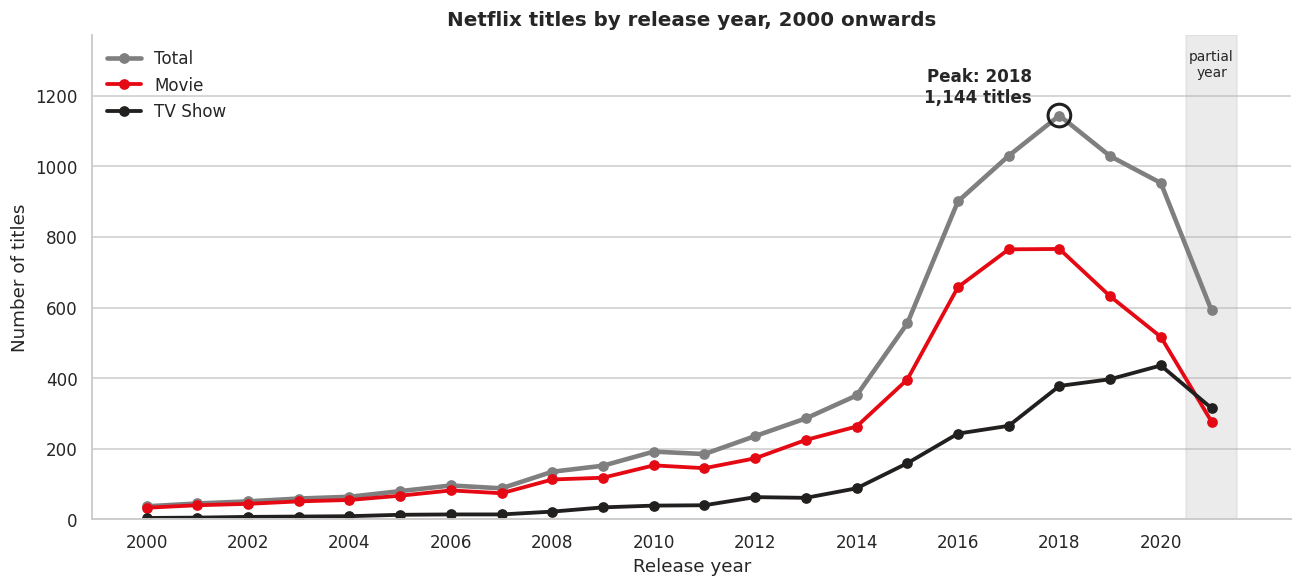

In [ ]:
m = yearly.loc[2000:]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(m.index, m["Total"], color="#7f7f7f", linewidth=3, marker="o", label="Total")
ax.plot(m.index, m["Movie"], color=NETFLIX_RED, linewidth=2.5, marker="o", label="Movie")
ax.plot(m.index, m["TV Show"], color=NETFLIX_DARK, linewidth=2.5, marker="o", label="TV Show")

ax.set_ylim(0, m["Total"].max() * 1.2)
ax.axvspan(PARTIAL_YEAR - 0.5, PARTIAL_YEAR + 0.5, color=GREY, alpha=0.25)
ax.text(PARTIAL_YEAR, ax.get_ylim()[1] * 0.97, "partial\nyear", ha="center", va="top", fontsize=9)
peak_val = yearly.loc[peak_year, "Total"]
ax.scatter([peak_year], [peak_val], s=220, facecolors="none", edgecolors=NETFLIX_DARK, linewidths=2, zorder=5)   # ring around the peak
ax.annotate(f"Peak: {peak_year}\n{int(peak_val):,} titles", xy=(peak_year, peak_val), xytext=(-18, 6),
            textcoords="offset points", ha="right", va="bottom", fontsize=11, fontweight="bold")

ax.set_xticks(range(2000, PARTIAL_YEAR + 1, 2))
ax.set_title("Netflix titles by release year, 2000 onwards")
ax.set_xlabel("Release year"); ax.set_ylabel("Number of titles")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); save_fig("01_release_year_trend"); plt.show()

### 4b. The long view, and year-over-year growth

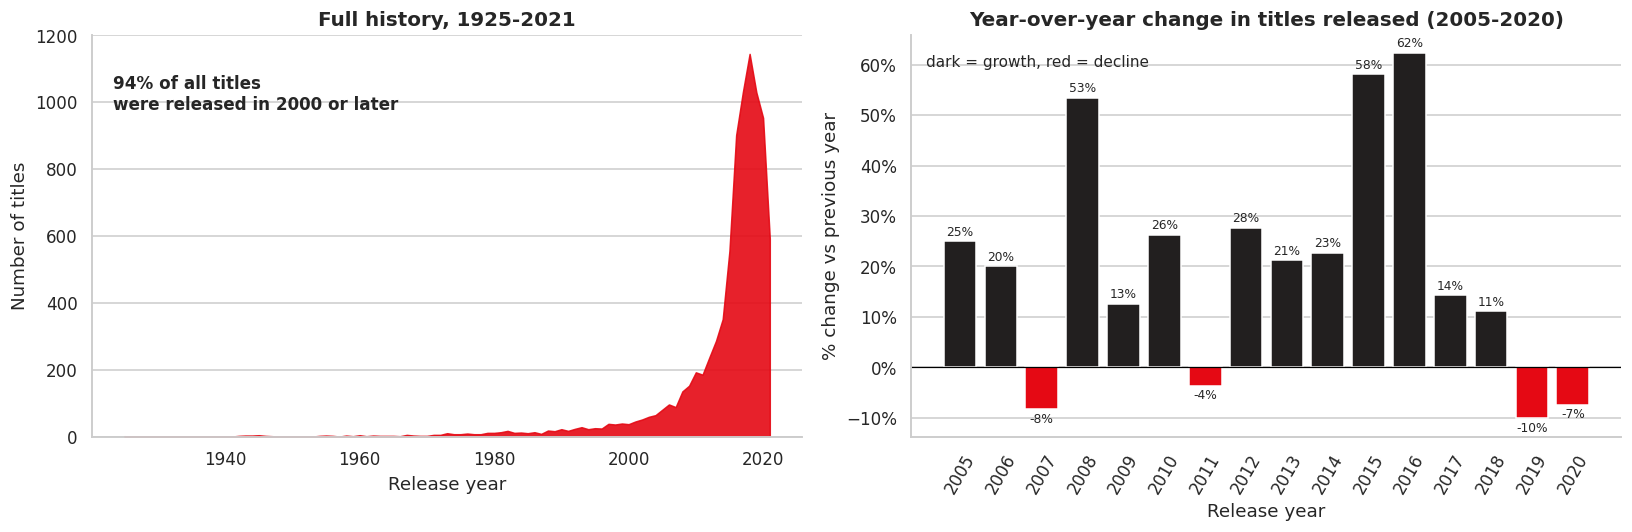

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Full history
axes[0].fill_between(yearly.index, yearly["Total"], color=NETFLIX_RED, alpha=0.9)
axes[0].set_ylim(bottom=0)
axes[0].set_title(f"Full history, {first}-{last}")
axes[0].set_xlabel("Release year"); axes[0].set_ylabel("Number of titles")
axes[0].text(0.03, 0.9, f"{(df['release_year'] >= 2000).mean():.0%} of all titles\nwere released in 2000 or later",
             transform=axes[0].transAxes, fontsize=11, fontweight="bold", va="top")

# YoY % change, complete years only
yoy = modern.loc[2005:, "yoy_%"]
bar_colors = [NETFLIX_DARK if v >= 0 else NETFLIX_RED for v in yoy]
bars = axes[1].bar(yoy.index.astype(str), yoy.values, color=bar_colors)
axes[1].bar_label(bars, fmt="%.0f%%", fontsize=8, padding=2)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title(f"Year-over-year change in titles released (2005-{LAST_COMPLETE})")
axes[1].set_xlabel("Release year"); axes[1].set_ylabel("% change vs previous year")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1].tick_params(axis="x", rotation=60)
axes[1].text(0.02, 0.95, "dark = growth, red = decline", transform=axes[1].transAxes, fontsize=10, va="top")

plt.tight_layout(); save_fig("02_long_view_and_yoy"); plt.show()

### 4c. By decade, and "when made" vs "when added to Netflix"
Release year tells us when a title was **made**; `year_added` tells us when Netflix **put it on the platform**. Comparing the two separates *industry production* from *Netflix's catalogue strategy*.

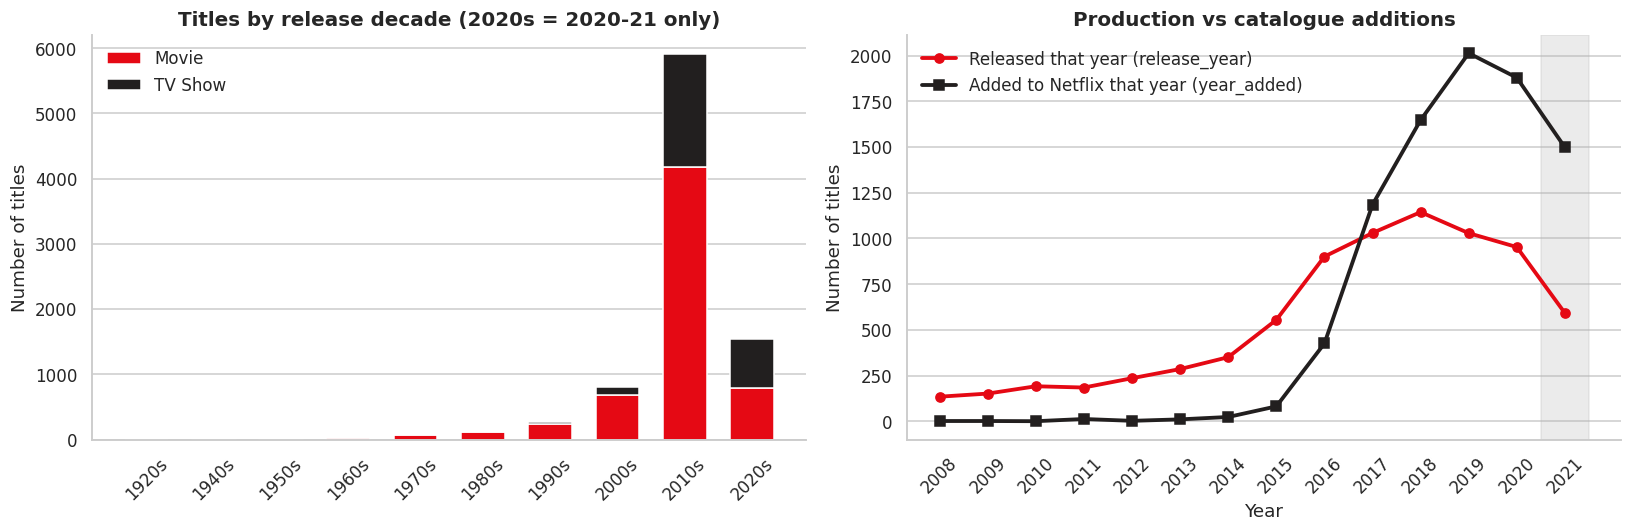

In [ ]:
added = df.groupby("year_added").size()
released = yearly["Total"]
yrs = range(2008, PARTIAL_YEAR + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# decades (stacked)
x = np.arange(len(by_decade))
axes[0].bar(x, by_decade["Movie"], color=NETFLIX_RED, label="Movie", width=0.65)
axes[0].bar(x, by_decade["TV Show"], bottom=by_decade["Movie"], color=NETFLIX_DARK, label="TV Show", width=0.65)
axes[0].set_xticks(x); axes[0].set_xticklabels(by_decade.index, rotation=45)
axes[0].set_title("Titles by release decade (2020s = 2020-21 only)")
axes[0].set_ylabel("Number of titles"); axes[0].legend(frameon=False)

# released vs added
axes[1].plot(list(yrs), [released.get(y, 0) for y in yrs], color=NETFLIX_RED, marker="o", linewidth=2.5, label="Released that year (release_year)")
axes[1].plot(list(yrs), [added.get(y, 0) for y in yrs], color=NETFLIX_DARK, marker="s", linewidth=2.5, label="Added to Netflix that year (year_added)")
axes[1].axvspan(PARTIAL_YEAR - 0.5, PARTIAL_YEAR + 0.5, color=GREY, alpha=0.25)
axes[1].set_xticks(list(yrs)[::1]); axes[1].tick_params(axis="x", rotation=45)
axes[1].set_title("Production vs catalogue additions"); axes[1].set_xlabel("Year"); axes[1].set_ylabel("Number of titles")
axes[1].legend(frameon=False, loc="upper left")

plt.tight_layout(); save_fig("03_decades_and_added_vs_released"); plt.show()

### 4d. Seasonality and freshness
* **Heatmap:** in which months does Netflix add the most content?
* **Lag chart:** how many years pass between a title's release and its arrival on Netflix?

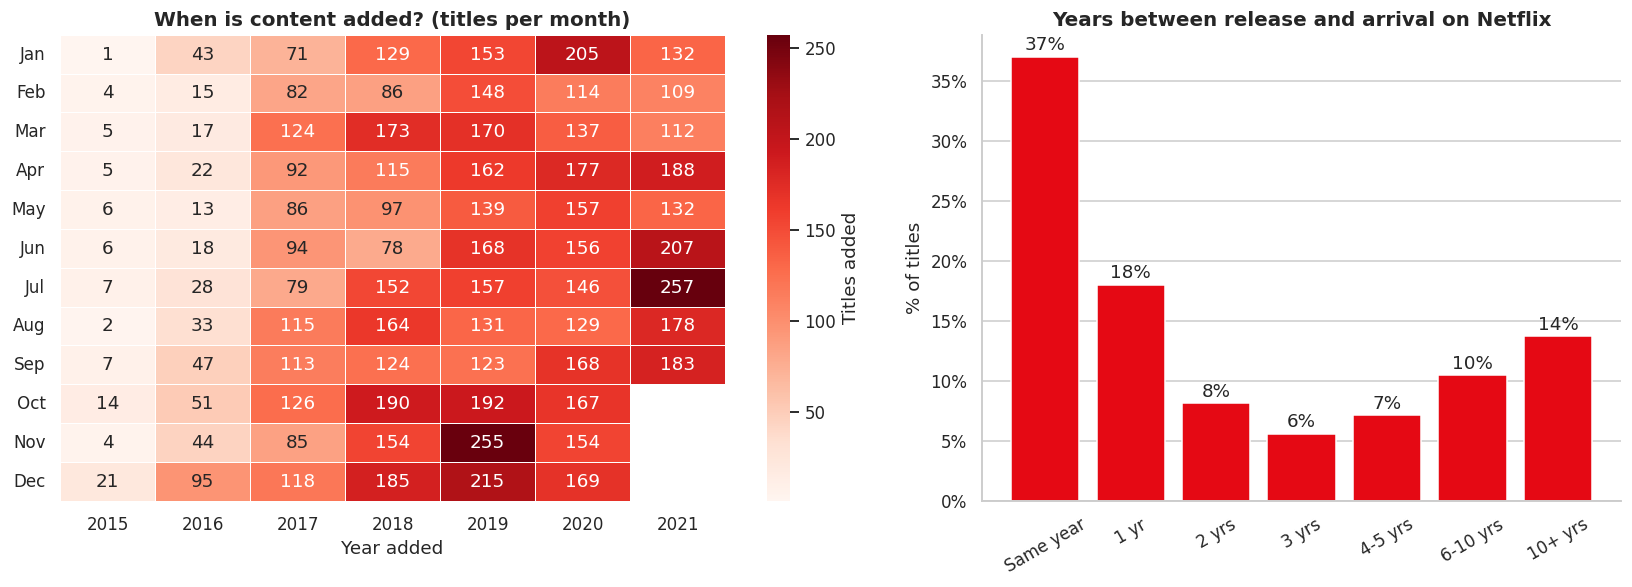

In [ ]:
# ---- seasonality: titles added per month, per year ----
max_date = df["date_added"].max()
season = (df[df["year_added"] >= 2015]
          .pivot_table(index="month_added", columns="year_added", values="show_id", aggfunc="count", fill_value=0)
          .reindex(range(1, 13), fill_value=0).astype(float))
season.loc[season.index > max_date.month, max_date.year] = np.nan          # months that haven't happened yet: blank, not zero
season.index = [calendar.month_abbr[i] for i in season.index]

# ---- freshness: years between release and arrival on Netflix ----
lag = (df["year_added"] - df["release_year"]).clip(lower=0)               # a handful of titles were added before release year -> 0
lag_bins = pd.cut(lag, bins=[-1, 0, 1, 2, 3, 5, 10, 200], labels=["Same year", "1 yr", "2 yrs", "3 yrs", "4-5 yrs", "6-10 yrs", "10+ yrs"])
lag_share = lag_bins.value_counts(normalize=True).sort_index() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

sns.heatmap(season, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, ax=axes[0], cbar_kws={"label": "Titles added"})
axes[0].set_title("When is content added? (titles per month)"); axes[0].set_xlabel("Year added"); axes[0].set_ylabel("")
axes[0].grid(False); axes[0].tick_params(axis="y", rotation=0)

bars = axes[1].bar(lag_share.index.astype(str), lag_share.values, color=NETFLIX_RED)
axes[1].bar_label(bars, fmt="%.0f%%", padding=2)
axes[1].set_title("Years between release and arrival on Netflix"); axes[1].set_ylabel("% of titles")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout(); save_fig("04_seasonality_and_lag"); plt.show()

In [ ]:
# save the yearly tables for your report
yearly.to_csv(OUT_DIR / "yearly_releases.csv")
growth.to_csv(OUT_DIR / "growth_rates_by_phase.csv")
by_decade.to_csv(OUT_DIR / "decade_summary.csv")

---
## Step 5 – Interpret business patterns
Facts below are computed from the data. The *interpretation* (the "why") is hedged – the dataset shows **what** happened, not **why**.

In [ ]:
tv_share_2015 = yearly.loc[2015, "TV Show"] / yearly.loc[2015, "Total"] * 100
tv_share_last = yearly.loc[LAST_COMPLETE, "TV Show"] / yearly.loc[LAST_COMPLETE, "Total"] * 100
g = growth.rename(columns=lambda c: c.replace(" CAGR %", ""))
boom, post = f"2015 -> 2018", f"2018 -> {LAST_COMPLETE}"

month_totals = df[df["year_added"].between(2016, LAST_COMPLETE)].groupby("month_added").size()
busiest_month = calendar.month_name[int(month_totals.idxmax())]; quietest_month = calendar.month_name[int(month_totals.idxmin())]
within_1yr = (lag <= 1).mean() * 100
back_catalogue = (lag >= 6).mean() * 100

insights = [
    f"**A recent-content library.** {(df['release_year'] >= 2000).mean():.0%} of titles were released in 2000 or later and {(df['release_year'] >= 2015).mean():.0%} in 2015 or later.",
    f"**Rapid growth, then a peak.** Titles released per year grew by about {g.loc[boom, 'Total']:.0f}% per year between 2015 and 2018, peaking in {peak_year} with {int(yearly.loc[peak_year, 'Total']):,} titles.",
    f"**Movies and TV diverged after the peak.** Movie releases fell ({g.loc[post, 'Movie']:.0f}% per year from 2018 to {LAST_COMPLETE}) while TV Shows kept growing ({g.loc[post, 'TV Show']:+.0f}% per year), lifting TV's share of releases from {tv_share_2015:.0f}% in 2015 to {tv_share_last:.0f}% in {LAST_COMPLETE}.",
    f"**Fresh content.** {within_1yr:.0f}% of titles arrive on Netflix within a year of release (median lag: {lag.median():.0f} year), so the catalogue mirrors recent production - while {back_catalogue:.0f}% are 6+ years old (licensed back-catalogue).",
    f"**Seasonality.** Across {2016}-{LAST_COMPLETE}, {busiest_month} had the most additions and {quietest_month} the fewest.",
]
display(Markdown("\n\n".join(f"{i}. {t}" for i, t in enumerate(insights, 1))))

1. **A recent-content library.** 94% of titles were released in 2000 or later and 71% in 2015 or later.

2. **Rapid growth, then a peak.** Titles released per year grew by about 27% per year between 2015 and 2018, peaking in 2018 with 1,144 titles.

3. **Movies and TV diverged after the peak.** Movie releases fell (-18% per year from 2018 to 2020) while TV Shows kept growing (+7% per year), lifting TV's share of releases from 29% in 2015 to 46% in 2020.

4. **Fresh content.** 55% of titles arrive on Netflix within a year of release (median lag: 1 year), so the catalogue mirrors recent production - while 24% are 6+ years old (licensed back-catalogue).

5. **Seasonality.** Across 2016-2020, December had the most additions and February the fewest.

### Reading the patterns as a business analyst
* **Why the 2015-2018 boom?** It coincides with Netflix's global expansion and its push into original production – plausible drivers, but not provable from this file alone.
* **Why the decline after 2018?** Possible factors include the **COVID-19 production slowdown (2020)**, a shift from quantity to quality, and a preference for long-running series (note TV's continued growth). The dataset cannot prove cause – present these as hypotheses.
* **Be careful with "decline":** the dataset is a *snapshot*. Titles released recently may not have reached the catalogue yet, and licensed titles can expire – so the most recent years can look smaller than they ultimately will be.

---
## ✅ Summary
Organised titles by release year, calculated yearly volumes, measured growth with YoY change, rolling averages and CAGR, built trend visuals (line, area, YoY bars, decade stack, seasonality heatmap, freshness chart) and interpreted the patterns – while treating the partial 2021 data honestly.
Outputs are saved in `outputs/task4_trend_analysis/`.